In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ydata_profiling import ProfileReport
# from sklearn.model_selection import train_test_split,cross_val_score
# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer

from sklearn.preprocessing import StandardScaler, MinMaxScaler
# ,OneHotEncoder,RobustScaler
# from sklearn.linear_model import LinearRegression,SGDRegressor
# from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error

In [25]:
# problem 1
df=pd.read_csv("./datasets/Housing.csv")
print(df.sample())

       price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
365  3703000  5450         2          1        1      yes        no       no   

    hotwaterheating airconditioning  parking prefarea furnishingstatus  
365              no              no        0       no        furnished  


In [3]:
profile=ProfileReport(df,title='Housing Price Profile Report')
profile.to_file('housing_report.html')

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 13/13 [00:00<00:00, 481.26it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

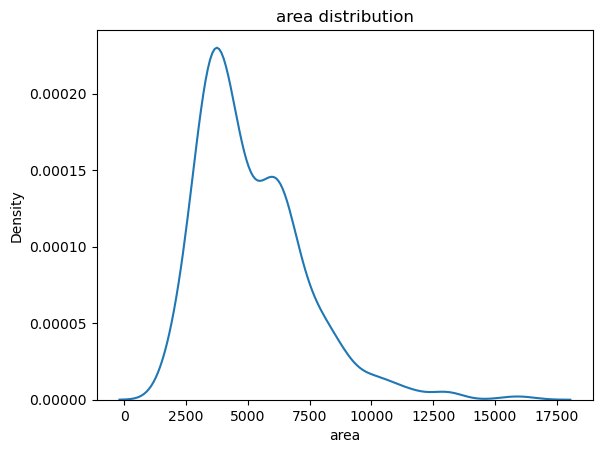

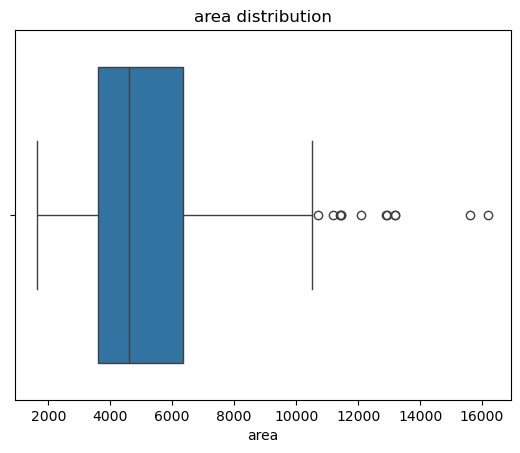

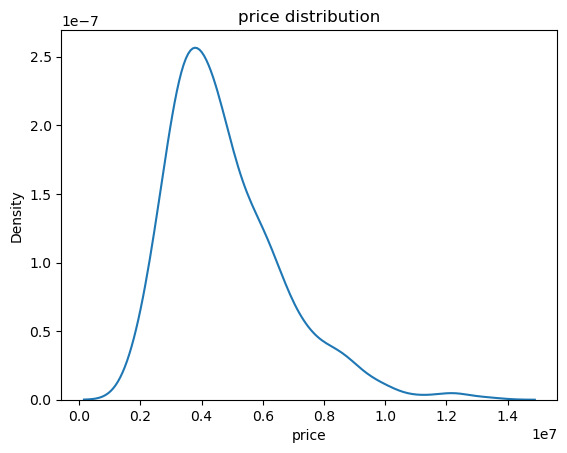

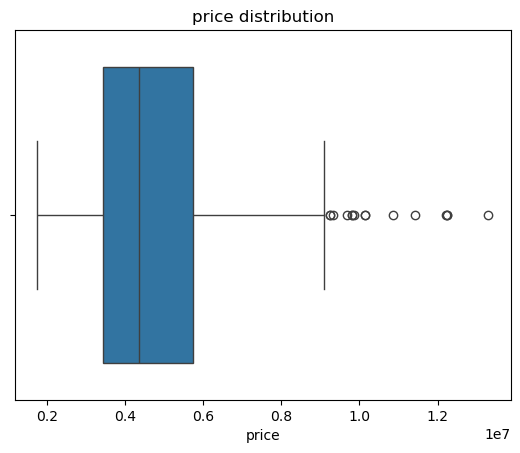

In [26]:
%matplotlib inline
# check kde
sns.kdeplot(data=df,x='area')
plt.title('area distribution')
plt.show()
sns.boxplot(data=df,x='area')
plt.title('area distribution')
plt.show()


sns.kdeplot(data=df,x='price')
plt.title('price distribution')
plt.show()
sns.boxplot(data=df,x='price')
plt.title('price distribution')
plt.show()


In [27]:
# outlier handling help taken by gpt

area_q1 = df["area"].quantile(0.25)
area_q3 = df["area"].quantile(0.75)
area_iqr = area_q3 - area_q1

price_q1 = df["price"].quantile(0.25)
price_q3 = df["price"].quantile(0.75)
price_iqr = price_q3 - price_q1

mask = (
    (df["area"] >= area_q1 - 1.5 * area_iqr) &
    (df["area"] <= area_q3 + 1.5 * area_iqr) &
    (df["price"] >= price_q1 - 1.5 * price_iqr) &
    (df["price"] <= price_q3 + 1.5 * price_iqr)
)

df_clean = df[mask]

X = df_clean["area"].to_numpy()
y = df_clean["price"].to_numpy()







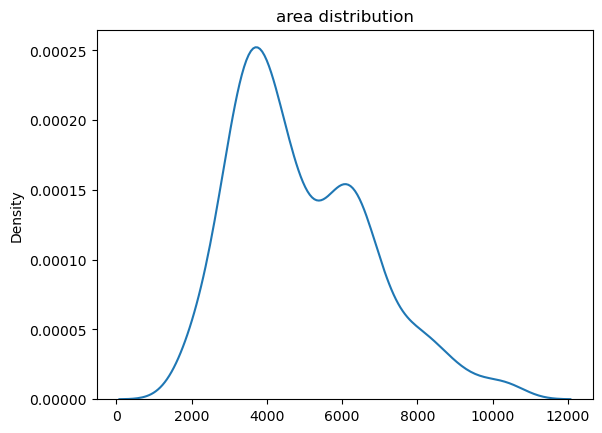

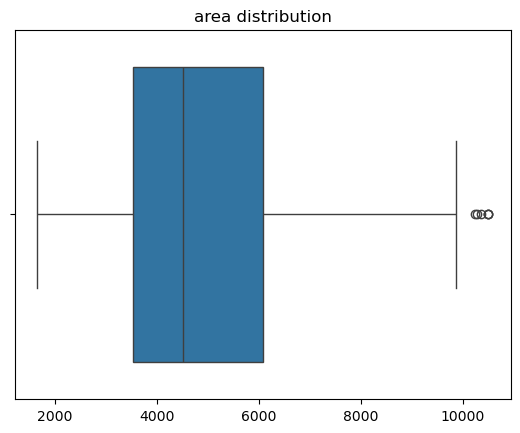

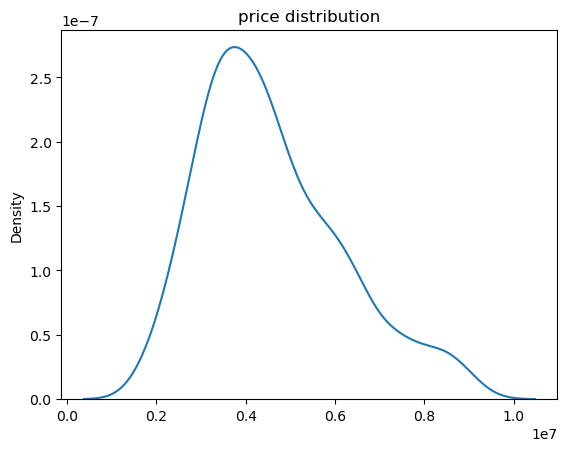

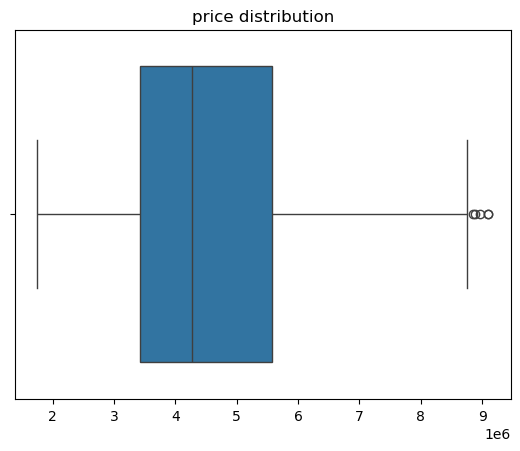

In [28]:
sns.kdeplot(x=X)
plt.title('area distribution')
plt.show()
sns.boxplot(x=X)
plt.title('area distribution')
plt.show()


sns.kdeplot(x=y)
plt.title('price distribution')
plt.show()
sns.boxplot(x=y)
plt.title('price distribution')
plt.show()

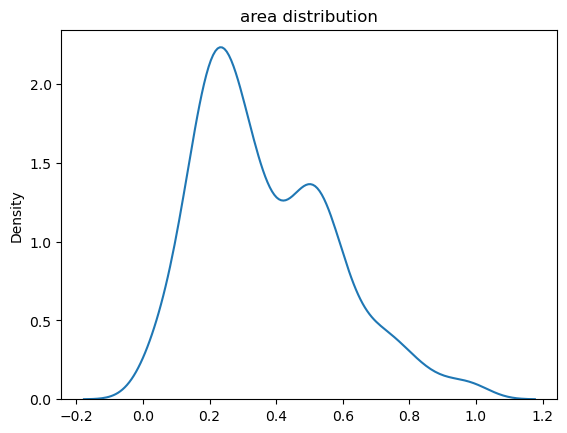

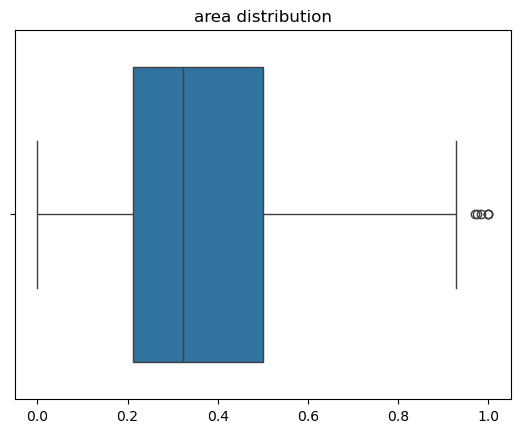

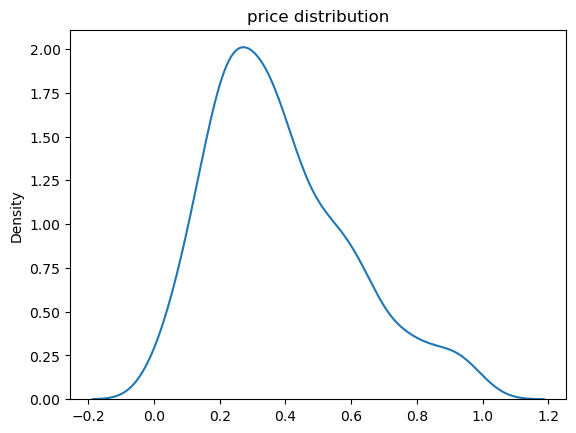

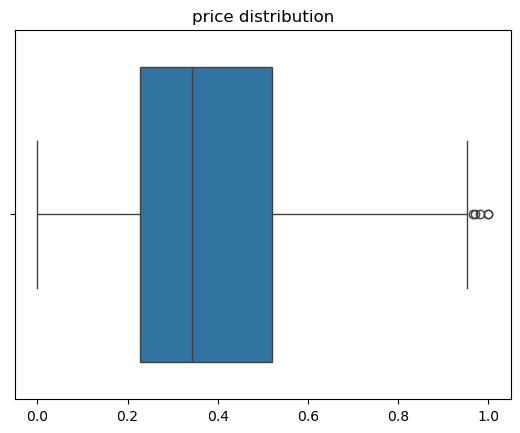

In [29]:
# scaling
area_min=X.min()
area_max=X.max()
X=(X-area_min)/(area_max-area_min)

# price scaling
price_min=y.min()
price_max=y.max()
y=(y-price_min)/(price_max-price_min)
# print(area_scaled)
sns.kdeplot(x=X)
plt.title('area distribution')
plt.show()
sns.boxplot(x=X)
plt.title('area distribution')
plt.show()

sns.kdeplot(x=y)
plt.title('price distribution')
plt.show()
sns.boxplot(x=y)
plt.title('price distribution')
plt.show()

In [8]:
# phitron class pattern

def make_pred(x,w,b):
    m=x.shape[0]
    prediction=np.zeros(m)
    for i in range(m):
        pre=w*x[i]+b
        prediction[i]=pre
    return prediction

def compute_cost(x,y,w,b):
    m=x.shape[0]
    cost=0
    for i in range(m):
        pred=w*x[i]+b
        error=y[i]-pred
        cost+=(error**2)
    return cost/(2*m)

def calc_gradient(x,y,w,b):
    m=x.shape[0]
    dj_dw=0
    dj_db=0
    for i in range(m):
        pred=x[i]*w+b
        error=pred-y[i]
        dj_dw+=(error*x[i])
        dj_db+=error
    return dj_dw/m,dj_db/m

def gradient_descentent(x,y,w,b,max_iter,alpha):
    cost_memo=[]
    iter_list=[]
    pred_hist=[]
    for i in range(max_iter):
        dj_dw,dj_db=calc_gradient(x,y,w,b)
        w=w-(alpha*dj_dw)
        b=b-(alpha*dj_db) 
        cost=compute_cost(x,y,w,b)
        cost_memo.append(cost)
        iter_list.append(i)
        if i%200==0:
            print(f"iteration{i}: Cost {cost}, w:{w}, b:{b}\n")
    return w,b,cost_memo,iter_list
    
        

In [9]:
w_final,b_final,cost_memo,iter_list=gradient_descentent(area_scaled,price_scaled,w=0,b=0,max_iter=1000,alpha=0.1)


iteration0: Cost 0.08177144149720073, w:0.017220684136852564, b:0.038784531895777255

iteration200: Cost 0.017108418435712876, w:0.3739612150708559, b:0.2493032926374905

iteration400: Cost 0.016357727238500593, w:0.48549520334327456, b:0.20539982744760996

iteration600: Cost 0.016191653782719542, w:0.5379550095527232, b:0.18474991335488855

iteration800: Cost 0.01615491378521126, w:0.562629382900557, b:0.17503726424806193



In [30]:
# gpt generated

def predict(X,w,b):
    return w*X+b

def compute_cost(X,y,w,b):
    m=len(X)
    predictions=predict(X,w,b)
    errors=predictions-y
    return np.sum(errors**2)/(2*m)

# Gradient
def compute_gradient(X, y, w, b):
    m = len(X)

    predictions = predict(X, w, b)
    errors = predictions - y

    dj_dw = np.sum(errors * X) / m
    dj_db = np.sum(errors) / m

    return dj_dw, dj_db

# Gradient Descent
def gradient_descent(X, y, w, b, alpha, iterations):

    cost_history = []

    for i in range(iterations):

        dj_dw, dj_db = compute_gradient(X, y, w, b)

        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        cost = compute_cost(X, y, w, b)
        cost_history.append(cost)

    return w, b, cost_history

# 7. Random initialization
w = np.random.randn()
b = np.random.randn()

initial_cost = compute_cost(X, y, w, b)

print("Initial w:", w)
print("Initial b:", b)
print("Initial cost:", initial_cost)


# 8. Train
alpha = 0.1
iterations = 1000

w, b, cost_history = gradient_descent(
    X, y, w, b, alpha, iterations
)

print("Final w:", w)
print("Final b:", b)

Initial w: -0.2542233377289816
Initial b: 0.06018499092094055
Initial cost: 0.11841691631827977
Final w: 0.5439383969249106
Final b: 0.18369406918758582


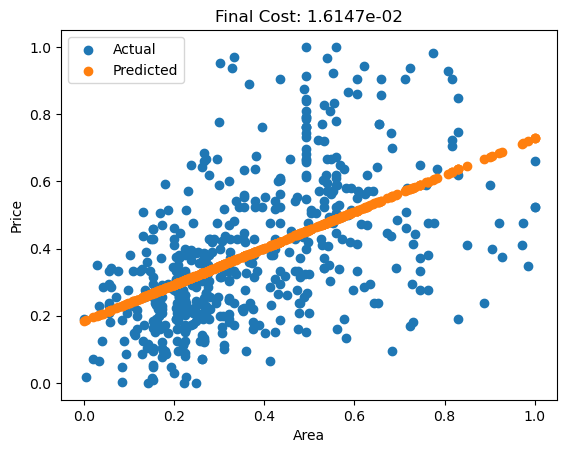

In [36]:
# Actual vs predicted
y_pred = predict(X, w, b)

plt.scatter(X, y, label="Actual")
plt.scatter(X, y_pred, label="Predicted")
plt.xlabel("Area")
plt.ylabel("Price")
# sns.scatterplot(x=X,y=y,label="Actual2")
# plt.plot(X,y_pred,color='red',label='Best fit line')
plt.title(f"Final Cost: {compute_cost(area_scaled,price_scaled, w_final, b_final):0.4e}")
plt.legend()
plt.show()
     


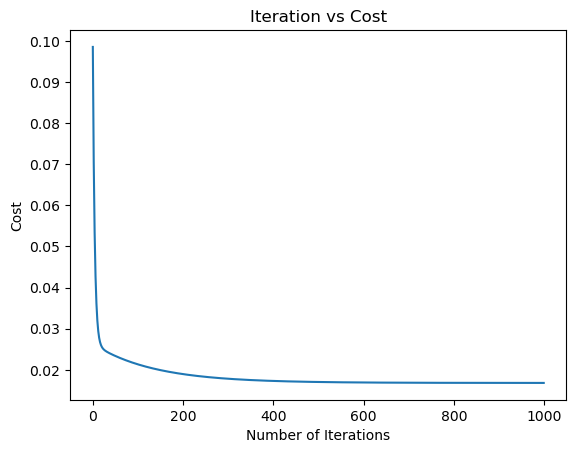

In [32]:
# Plot the cost over the first 20 iterations to see it dropping
# iteration vs cost graph
# plt.plot(iter_list, cost_memo)
plt.plot(range(1000),cost_history)
plt.xlabel("Number of Iterations")
plt.ylabel("Cost")
plt.title("Iteration vs Cost")
plt.show()

In [ ]:
# problem 5
columns=["mpg","cylinders","displacement","horsepower","weight","acceleration","model_year","origin","car_name"]
df=pd.read_fwf("./datasets/auto+mpg/auto-mpg.data",header=None,names=columns)
# df=pd.read_csv("./datasets/auto+mpg/auto-mpg.data",header=None,sep=r'\s+',names=columns)
df.sample(2)